# NEU-DET surface defect detection baseline

This notebook reads the recorded results of `neu-det-baseline-20261019`.
It needs the pinned CPU Python environment, but no model downloads, dataset,
GPU, or retraining. The JSON snapshot contains real training history, separate
validation/test reports, ONNX verification, prior failures and hashes of retained artifacts.

The training recipe was fixed before test evaluation. Selection uses validation
mAP@0.5:0.95; the held-out test set is evaluated after selecting the checkpoint.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "docs/results/neu-det-baseline-20261019.json").is_file())
result = json.loads((root / "docs/results/neu-det-baseline-20261019.json").read_text())
run, history = result["training"], result["history"]
validation, test = result["validation"], result["test"]
verification = result["onnx"]["verification"]
assert run["status"] == "completed" and not run["smoke_run"]
assert validation["split"] == "val" and test["split"] == "test"
assert validation["checkpoint_sha256"] == test["checkpoint_sha256"] == run["checkpoint_sha256"]
assert result["onnx"]["metadata"]["checkpoint_sha256"] == test["checkpoint_sha256"]
assert test["checkpoint_epoch"] == run["best_epoch"]
print("Run:", result["run_id"])
print("Training source:", result["source_commit"])
print("Evaluation source:", result["evaluation_source_commit"])
print("Final export source:", result["export_source_commit"])
print("Manifest SHA-256:", run["manifest_sha256"])


Run: neu-det-baseline-20261019
Training source: c25334daf2dd18d97550943f92bbfe501d61882b
Evaluation source: 97149a668210fe0c94483039d5034f8c3d62d081
Final export source: b21e4c593c05f843c111146fb96faff9688d23cb
Manifest SHA-256: 8bf7bfca0af99f0af4decdbdab53a423fcf32ac34822d7cf6d3963c059859615


## Data and model choices

The 1,800 NEU-DET images are split reproducibly by filename family and exact pixel
groups. This custom split is not an official benchmark. Two identical images with
different annotations remain together in the test split. Without acquisition or
parent-image IDs, exact-pixel grouping cannot prove full independence.

All difficult and truncated boxes are ordinary targets. Ultralytics removes one
duplicate label row from training: 2,909 manifest boxes become 2,908 effective
training boxes. Validation has no removed rows; test has two removed rows (one crazing, one
patches), leaving 653 effective test boxes.

Pretrained YOLOv8s provides a small one-stage detector for the shared manifest
pipeline. Training uses 640-pixel inputs, batch 16, one remote RTX A6000 and
float16 AMP. Flips stay disabled to preserve defect orientation. Mosaic, scale,
translation and HSV augmentation retain the pinned library defaults; mosaic
stops for the final 10 epochs. The automatic optimizer resolves to AdamW.


In [2]:
for split in ("train", "val", "test"):
    counts = result["dataset"]["counts"][split]
    print(f"{split:5s}: {counts['images']:4d} images, {sum(counts['boxes_by_class'].values()):4d} manifest boxes")
print("Training loader:", run["loader_audit"]["train"])
print("Model:", run["model_name"])
print("Config:", json.dumps(run["effective_config"], indent=2))
optimizer = result["resolved_optimizer"]
print(f"Resolved optimizer: {optimizer['name']}, lr={optimizer['learning_rate']}, weight decay={optimizer['weight_decay']}")
print(f"Training wall time: {result['execution']['training_wall_seconds']/60:.2f} minutes")


train: 1259 images, 2909 manifest boxes
val  :  270 images,  625 manifest boxes
test :  271 images,  655 manifest boxes
Training loader: {'images': 1259, 'manifest_boxes': 2909, 'effective_boxes': 2908, 'duplicate_rows_removed': 1}
Model: yolov8s
Config: {
  "epochs": 100,
  "image_size": 640,
  "batch_size": 16,
  "patience": 20,
  "seed": 42,
  "workers": 4,
  "cpu_threads": 2,
  "device": "cuda",
  "horizontal_flip": false,
  "vertical_flip": false,
  "fast_dev_run": false
}
Resolved optimizer: AdamW, lr=0.001, weight decay=0.0005
Training wall time: 15.27 minutes


## Learning curves and selection

The checkpoint comes from the highest validation mAP@0.5:0.95 (later epoch wins a
tie). These curves show the trainer's validation path. The separate CPU reports
below use float32 and fixed square letterboxing; trainer validation and its final
recheck can differ in padding, precision and model fusion. Their numbers are
labelled separately rather than treated as an exact numerical reproduction.

Training losses use augmentation; validation losses use ordinary images.


Completed 100 epochs; selected 96; best selection fitness=0.43982
Successful optimizer updates: 2021
AMP overflow-skipped updates: 10


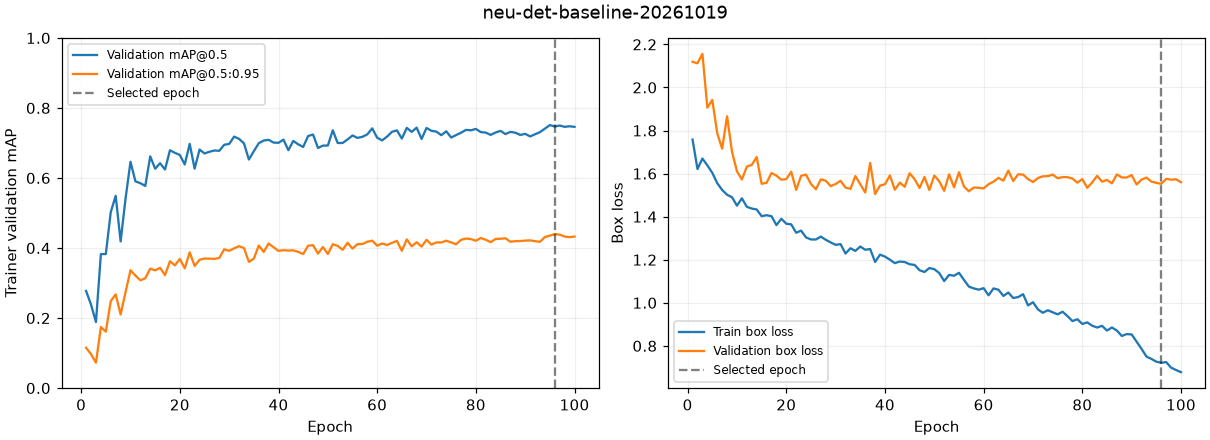

In [3]:
best = run["best_epoch"]
assert best == max(history, key=lambda row: (row["fitness"], row["epoch"]))["epoch"]
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for key, label in (("metrics/mAP50(B)", "Validation mAP@0.5"),
                   ("metrics/mAP50-95(B)", "Validation mAP@0.5:0.95")):
    axes[0].plot(epochs, [row["metrics"][key] for row in history], label=label)
for key, label in (("train/box_loss", "Train box loss"), ("val/box_loss", "Validation box loss")):
    axes[1].plot(epochs, [row["metrics"][key] for row in history], label=label)
for axis in axes:
    axis.axvline(best, color="black", linestyle="--", alpha=.5, label="Selected epoch")
    axis.set_xlabel("Epoch")
    axis.grid(alpha=.2)
    axis.legend(fontsize=8)
axes[0].set(ylabel="Trainer validation mAP", ylim=(0, 1))
axes[1].set_ylabel("Box loss")
fig.suptitle(result["run_id"])
plt.show()
print(f"Completed {len(history)} epochs; selected {best}; best selection fitness={run['best_fitness']:.5f}")
print("Successful optimizer updates:", run["optimizer_steps"])
print("AMP overflow-skipped updates:", run["skipped_optimizer_steps"])


## Held-out detection results

AP uses a confidence floor of 0.001, NMS IoU 0.7 and at most 300 detections/image.
mAP@0.5:0.95 averages ten IoU thresholds. Each of the six classes has test targets.
Fixed precision and recall instead use confidence 0.25 and matching IoU 0.5,
rematching after confidence filtering. These are object-level counts, not an
image-classification confusion matrix or the trainer's best-F1 precision/recall.


Split     Images  Boxes     mAP50   mAP50-95  Precision    Recall
val          270    625    0.7194     0.4116     0.6008    0.7488
test         271    653    0.7427     0.4105     0.6391    0.7565

Test object metrics (fixed confidence 0.25):
crazing          n=105 AP50=0.3861 AP50-95=0.1638 TP= 52 FP= 84 FN= 53
inclusion        n=157 AP50=0.7860 AP50-95=0.4131 TP=121 FP= 46 FN= 36
patches          n=140 AP50=0.8721 AP50-95=0.5463 TP=122 FP= 41 FN= 18
pitted_surface   n= 63 AP50=0.9152 AP50-95=0.5673 TP= 56 FP= 17 FN=  7
rolled-in_scale  n=100 AP50=0.5974 AP50-95=0.2600 TP= 63 FP= 52 FN= 37
scratches        n= 88 AP50=0.8993 AP50-95=0.5123 TP= 80 FP= 39 FN=  8
Test mAP@0.5 >= 0.70: True


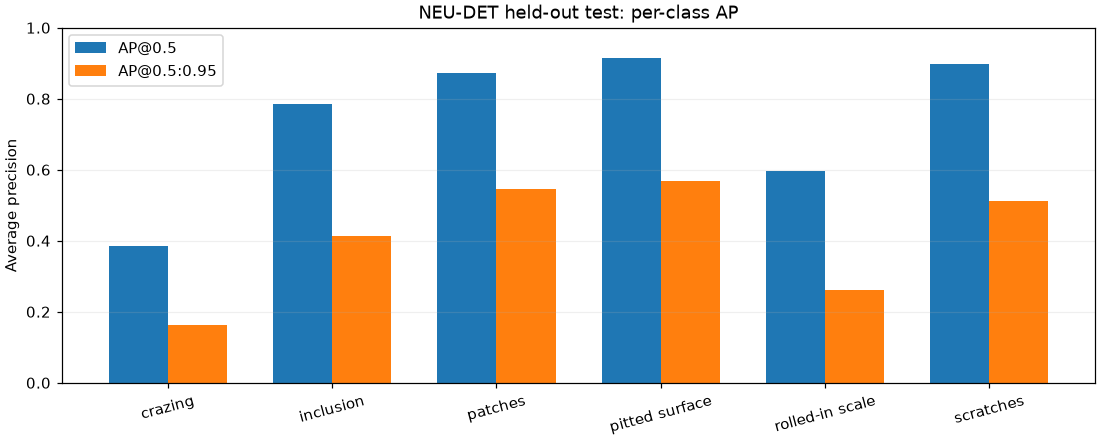

In [4]:
print(f"{'Split':8s} {'Images':>7s} {'Boxes':>6s} {'mAP50':>9s} {'mAP50-95':>10s} {'Precision':>10s} {'Recall':>9s}")
for report in (validation, test):
    m, audit = report["metrics"], report["loader_audit"]
    fixed = m["fixed_threshold_micro"]
    print(f"{report['split']:8s} {audit['images']:7d} {fixed['support']:6d} {m['map50']:9.4f} {m['map50_95']:10.4f} {fixed['precision']:10.4f} {fixed['recall']:9.4f}")
rows = test["metrics"]["per_class"]
print("\nTest object metrics (fixed confidence 0.25):")
for row in rows:
    print(f"{row['class_name']:16s} n={row['support']:3d} AP50={row['ap50']:.4f} AP50-95={row['ap50_95']:.4f} TP={row['true_positives']:3d} FP={row['false_positives']:3d} FN={row['false_negatives']:3d}")
x = np.arange(len(rows))
fig, axis = plt.subplots(figsize=(10, 4), layout="constrained")
axis.bar(x-.18, [row["ap50"] for row in rows], width=.36, label="AP@0.5")
axis.bar(x+.18, [row["ap50_95"] for row in rows], width=.36, label="AP@0.5:0.95")
axis.set_xticks(x, [row["class_name"].replace("_", " ") for row in rows], rotation=15)
axis.set(ylabel="Average precision", ylim=(0, 1), title="NEU-DET held-out test: per-class AP")
axis.grid(axis="y", alpha=.2)
axis.legend()
plt.show()
print("Test mAP@0.5 >= 0.70:", test["metrics"]["map50"] >= .70)


## ONNX parity and CPU timing

The owner approved a plan amendment on 2026-10-19: detector box-coordinate
absolute tolerance is now **0.002 input pixels**; class-probability tolerance
remains **0.001**, with relative tolerance zero. The old 0.001 box gate failed:
one of 2,688,000 raw values per batch mode differed by 0.001007080078125 pixels.
Both failed attempts remain in the snapshot; the new pass does not imply the
original gate passed.

The reference is the ordinary fused float32 PyTorch inference model, with native
CPU kernels. Conv/BatchNorm fusion is also used by the evaluator. Only the export
copy uses ONNX-specific Detect/C2f paths. The float32 opset-17 graph has dynamic
batches, fixed 640 × 640 inputs and output `[batch, 10, 8400]`. Preprocessing and
NMS stay outside the graph.

Serving must read the metadata and disable ONNX Runtime graph optimizations
(`ORT_DISABLE_ALL`, CPUExecutionProvider). This trades potential speed for
numerical agreement. Weights, input pixels, all raw predictions, 32 test images
and batches 1/8 are preserved; no score filtering hides discrepancies.

Latency measures model-only CPU execution on the remote EPYC host, with two
threads, 10 warmups and 200 calls. It excludes decoding, preprocessing, NMS,
startup and network overhead. The plan's 50 ms CPU target is for the casting
classifier, not the detector.


In [5]:
assert result["onnx"]["status"] == "passed"
parity, latency = verification["parity"], verification["latency"]
assert parity["passed"] and parity["meets_32_test_image_check"]
assert parity["samples"] == 32 and parity["batch_sizes"] == [1, 8]
assert parity["max_box_absolute_error"] <= parity["box_absolute_tolerance"] == .002
assert parity["max_score_absolute_error"] <= parity["score_absolute_tolerance"] == .001
assert parity["relative_tolerance"] == 0
print("Maximum box error (input pixels):", parity["max_box_absolute_error"])
print("Maximum class-probability error:", parity["max_score_absolute_error"])
print("Approved box tolerance:", parity["box_absolute_tolerance"])
print("Original 0.001 box gate passed:", parity["max_box_absolute_error"] <= .001)
print("Runtime optimization:", verification["runtime"]["onnxruntime_graph_optimization"])
print("CPU:", verification["runtime"]["cpu_model"])
print(f"ONNX mean: {latency['mean_ms']:.2f} ms; p95: {latency['p95_ms']:.2f} ms")
print("Prior failed attempts retained:", len(result["onnx"]["previous_attempts"]))


Maximum box error (input pixels): 0.001007080078125
Maximum class-probability error: 2.5480985641479492e-06
Approved box tolerance: 0.002
Original 0.001 box gate passed: False
Runtime optimization: ORT_DISABLE_ALL
CPU: AMD EPYC 9124 16-Core Processor
ONNX mean: 187.49 ms; p95: 196.54 ms
Prior failed attempts retained: 2


## Reproduce and connect to the application

See [`docs/RESULTS.md`](../docs/RESULTS.md) for commands and retained artifacts.
The manifest defines frozen images, splits and labels; `vf_ml` trains, evaluates
and exports the selected checkpoint. Future workers will use this same package.
The API will manage jobs and metadata without importing PyTorch; the inference
service will consume ONNX and its preprocessing/class-map metadata.

The amended baseline gate is complete. Next is local Docker Compose for
PostgreSQL, MinIO and Redis. Heavy training stays on the VM in the tested user-owned Python environment,
without sudo or remote Docker. Active learning and notebook 03 follow later.
